In [1]:
import random
from transformers import AutoTokenizer, AutoModelForCausalLM, LogitsProcessor,LogitsProcessorList

import torch
from transformers import BitsAndBytesConfig
from tqdm import tqdm
from pathlib import Path
import datasets

/work/pi_mccallum_umass_edu/aparashar_umass_edu/.conda/envs/decoding-poc/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
qa_exemplars = [
  {
    "question": "What do people use to absorb extra ink from a fountain pen? Answer Choices: (a) shirt pocket (b) calligrapher’s hand (c) inkwell (d) desk drawer (e) blotter",
    "reasoning": "The answer must be an item that can absorb ink. Of the above choices, only blotters are used to absorb ink. So the answer is (e)",
    "answer": "e"
  },
  {
    "question": "What home entertainment equipment requires cable? Answer Choices: (a) radio shack (b) substation (c) television (d) cabinet",
    "reasoning": "The answer must require cable. Of the above choices, only television requires cable. So the answer is (c)",
    "answer": "c"
  },
  {
    "question": "The fox walked from the city into the forest, what was it looking for? Answer Choices: (a) pretty flowers (b) hen house (c) natural habitat (d) storybook",
    "reasoning": "The answer must be something in the forest. Of the above choices, only natural habitat is in the forest. So the answer is (c).",
    "answer": "c"
  },
  {
    "question": "Sammy wanted to go to where the people were. Where might he go? Answer Choices: (a) populated areas (b) race track (c) desert (d) apartment (e) roadblock",
    "reasoning": "The answer must be a place with a lot of people. Of the above choices, only populated areas have a lot of people. So the answer is (a).",
    "answer": "a"
  },
  {
    "question": "Where do you put your grapes just before checking out? Answer Choices: (a) mouth (b) grocery cart (c) super market (d) fruit basket (e) fruit market",
    "reasoning": "The answer should be the place where grocery items are placed before checking out. Of the above choices, grocery cart makes the most sense for holding grocery items. So the answer is (b)",
    "answer": "b"
  },
  {
    "question": "Google Maps and other highway and street GPS services have replaced what? Answer Choices: (a) united states (b) mexico (c) countryside (d) atlas",
    "reasoning": "The answer must be something that used to do what Google Maps and GPS services do, which is to give directions. Of the above choices, only atlases are used to give directions. So the answer is (d)",
    "answer": "d"
  },
  {
    "question": "Before getting a divorce, what did the wife feel who was doing all the work? Answer Choices: (a) harder (b) anguish (c) bitterness (d) tears (e) sadness",
    "reasoning": "The answer should be the feeling of someone getting divorced who was doing all the work. Of the above choices, the closest feeling is bitterness. So the answer is (c).",
    "answer": "c"
  }
]


In [3]:
from typing import Union,List

class TruncateLogitsProcessor(LogitsProcessor):
    def __init__(self,token_id: Union[int, List[int]],stop_word:Union[str, List[str]],eos_token_id: Union[int, List[int]],tokenizer):
        if isinstance(token_id, int):
            token_id = [token_id]
        if isinstance(eos_token_id, int):
            eos_token_id = [eos_token_id]
        # if not all(isinstance(i,int) for i in token_id) or any(i < 0 for i in token_id):
        #     logger.warning(f"`token_id` has to be a list of positive integers, but is {token_id}")
        self.stop_word = stop_word
        self.token_id = token_id
        
        self.eos_token_id = eos_token_id
        self.tokenizer = tokenizer
    def __call__(self,input_ids: torch.LongTensor, scores: torch.FloatTensor) -> torch.FloatTensor:
        cur_len = input_ids.shape[-1]
        
        # print(cur_len)
        # print(scores.shape)
        max_score_ids = torch.argmax(scores, dim=1)
        
        for i in range(len(max_score_ids)):
            #print(tokenizer.decode(max_score_ids[i]))
            if (max_score_ids[i] in tokenizer(self.stop_word).input_ids or self.tokenizer.decode(max_score_ids[i]).find(self.stop_word) != -1) :
                print("GITTT")
                scores[i][:] = -float('inf')
                scores[i][self.eos_token_id[0]] = 0
        #print(torch.argmax(scores, dim=1))
        # print(input_ids.shape)
        #print(input_ids)
        scores.to(input_ids.device)
        if torch.argmax(scores[:,]) in [894]:
            print('yes')
            scores = torch.zeros(scores.shape)
            scores[:, self.eos_token_id] = 1
                
        return scores



In [7]:
tokenizer.bos_token


'<bos>'

In [ ]:
data[0]
d = data[0]
    
    # prompt_arr = [default_fwd_input_prefix] +[default_fwd_question_prefix + d['input']]+[default_fwd_reasoning_prefix]
options_text = ['('+ l.lower() + ') ' + t  for l,t in zip(d['choices']['label'],d['choices']['text'])]
' '.join(options_text)

In [5]:
# default_instruction = "Answer the question with Yes or No: "
default_fwd_input_prefix = """Like each of the previous examples, answer the question with either of the answer choices provided.
Provide reasoning for your answer.
End your reasoning with the sentence: "So the answer is <your_answer_choice>". Replace "<your_answer_choice>" with your final answer, which should be one of the answer choice label letters (a,b,c,d,e,etc.)."""
# turn_prefix_model = '<start_of_turn>model'
# turn_prefix_human = '<start_of_turn>human'
# turn_suffix = '<end_of_turn>'
default_fwd_demos_prefix = "Here are some examples of reasoning based question answers."
default_fwd_reasoning_prefix = "Reasoning: "
default_fwd_question_prefix = "Question: "
default_fwd_target_prefix = "Answer: "
demos = random.sample(qa_exemplars,6)
demos = [[default_fwd_question_prefix + d["question"]]+ [default_fwd_reasoning_prefix + d["reasoning"] + default_fwd_target_prefix + d["answer"]] for d in demos]# def test(prompt_arr, model, tokenizer, data,demos, default_fwd_target_prefix, N = 10, temp = 0.5):
bnb_config= BitsAndBytesConfig(
            load_in_8bit=True,)
output_dict = {}
import json
# filepath = "/work/pi_dhruveshpate_umass_edu/aparashar_umass_edu/Arithmetic-Sampling/data/stratqa_data.json"
# datasets.config.DOWNLOADED_DATASETS_PATH = Path('/work/pi_dhruveshpate_umass_edu/aparashar_umass_edu/datasets')
dataset_name = 'tau/commonsense_qa'
split = 'validation'
data = datasets.load_dataset(dataset_name,'', split=split,cache_dir ='/work/pi_dhruveshpate_umass_edu/aparashar_umass_edu/datasets/.cache' )
        

demo_questions = [d['question'] for d in qa_exemplars]
print(len(data))
# data = [i for i in data if i['input'] not in demo_questions]
print(len(data))
# device_map="auto"
tokenizer = AutoTokenizer.from_pretrained("google/gemma-2b-it", use_fast=True)
model = AutoModelForCausalLM.from_pretrained("google/gemma-2b-it",
                                             # torch_dtype=torch.bfloat16,
                                             cache_dir = '/work/pi_mccallum_umass_edu/aparashar_umass_edu/models/.cache',
                                             # device_map="auto",
                                                # quantization_config=bnb_config
                                            ).to('cuda')
logits_processor = LogitsProcessorList(
    [
        #StopAfterTokenLogitsProcessor(token_id_to_stop=29973,max_length=40),
        TruncateLogitsProcessor(stop_word='Question',token_id=[tokenizer.encode('Question')],eos_token_id=tokenizer.eos_token_id,tokenizer=tokenizer),
    ])
# torch.device = 'cuda'
# set pad_token_id to eos_token_id because GPT2 does not have a EOS token
model.config.pad_token_id = model.config.eos_token_id
model.generation_config.pad_token_id = model.config.eos_token_id
for  idx,d in enumerate(tqdm(data, desc="Predicting")):
    print(d)
    d = data[0]
    options = ['('+ l.lower() + ') ' + t  for l,t in zip(d['choices']['label'],d['choices']['text'])]
    options_text = 'Answer choices: ' +' '.join(options)
    d['question'] += options_text
    # prompt_arr = [default_fwd_input_prefix] +[default_fwd_question_prefix + d['input']]+[default_fwd_reasoning_prefix]
    # options_text = [['('+ l[i] + ') ' + t[i] for i in len(d['choices']['labels'])] for l,t in zip(d['choices']['label'],d['choices']['text'])]
    prompt_arr = [default_fwd_input_prefix] +[default_fwd_question_prefix + d['question']]
    prompt_arr = demos + [prompt_arr]
    prompt_arr = [element for sublist in prompt_arr for element in sublist]
    # print(prompt_arr)
    input_prompt =  (' \n').join(prompt_arr)
    chat = [ { "role": "user", "content": input_prompt },]
    input_prompt = tokenizer.apply_chat_template(chat, tokenize=False, add_generation_prompt=True)


    print(f"prompt: {input_prompt}")
    input_ids = tokenizer(input_prompt, truncation=True, return_tensors="pt").input_ids.to('cuda')
    outputs_arith = model.generate(
        input_ids = input_ids,
        num_return_sequences = 5,
        do_sample = True,
        max_new_tokens = 200,
        temperature = 1.,
        num_beams = 1,
        return_dict_in_generate=True,
        logits_processor=logits_processor,
        use_arithmetic = True
        )
    outputs_sample = model.generate(
        input_ids = input_ids,
        num_return_sequences = 5,
        do_sample = True,
        temperature = 1.,
        num_beams = 1,
        max_new_tokens = 200,
        return_dict_in_generate=True,
        logits_processor=logits_processor,
        
        use_arithmetic = False
        )
    print(input_ids.shape[1])
    outputs_arith = [tokenizer.decode(o, skip_special_tokens=True)[len(input_prompt):] for o in outputs_arith.sequences]
    outputs_sample = [tokenizer.decode(o, skip_special_tokens=True)[len(input_prompt):] for o in outputs_sample.sequences]
    # print(f"Arithmetic output: {tokenizer.batch_decode(outputs_arith[input_ids.shape[1]:], skip_special_tokens=True)}")
    outputs_arith_str = '\n###\n'.join(outputs_arith)
    print("---")
    outputs_sample_str = '\n###\n'.join(outputs_sample)
    print(f"Arithmetic output: {outputs_arith_str}")
    print(f"Sample output: {outputs_sample_str}")
    

1221
1221


Predicting:   0%|                                                                                                                                                             | 0/1221 [00:00<?, ?it/s]


{'id': '1afa02df02c908a558b4036e80242fac', 'question': 'A revolving door is convenient for two direction travel, but it also serves as a security measure at a what?', 'question_concept': 'revolving door', 'choices': {'label': ['A', 'B', 'C', 'D', 'E'], 'text': ['bank', 'library', 'department store', 'mall', 'new york']}, 'answerKey': 'A'}
prompt: <bos><start_of_turn>user
Question: The fox walked from the city into the forest, what was it looking for? Answer Choices: (a) pretty flowers (b) hen house (c) natural habitat (d) storybook 
Reasoning: The answer must be something in the forest. Of the above choices, only natural habitat is in the forest. So the answer is (c).Answer: c 
Question: What home entertainment equipment requires cable? Answer Choices: (a) radio shack (b) substation (c) television (d) cabinet 
Reasoning: The answer must require cable. Of the above choices, only television requires cable. So the answer is (c)Answer: c 
Question: What do people use to absorb extra ink fr

ValueError: The following `model_kwargs` are not used by the model: ['use_arithmetic'] (note: typos in the generate arguments will also show up in this list)

In [6]:
!pip show transformers

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Name: transformers
Version: 4.40.0.dev0
Summary: State-of-the-art Machine Learning for JAX, PyTorch and TensorFlow
Home-page: https://github.com/huggingface/transformers
Author: The Hugging Face team (past and future) with the help of all our contributors (https://github.com/huggingface/transformers/graphs/contributors)
Author-email: transformers@huggingface.co
License: Apache 2.0 License
Location: /work/pi_mccallum_umass_edu/aparashar_umass_edu/.conda/envs/as02/lib/python3.9/site-packages
Requires: filelock, huggingface-hub, numpy, packaging, pyyaml, regex, requests, safetensors, tokenizers, tqdm
Required-by: 


In [6]:
!pip install --upgrade datasets


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.0/542.0 kB 1.1 MB/s eta 0:00:00a 0:00:01
  Using cached pyarrow_hotfix-0.6-py3-none-any.whl (7.9 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.0/172.0 kB 1.5 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.1/29.1 MB 6.4 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 401.2/401.2 kB 7.2 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 10.0.1
    Uninstalling pyarrow-10.0.1:
      Successfully uninstalled pyarrow-10.0.1
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2022.2.0
    Uninstalling fsspec-2022.2.0:
      Successfully uninstalled fsspec-2022.2.0
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface-hub 0.8.1
    Uninstalling huggingface-hub-0.8.1:
      Successfully uninstalled huggingface-hub-0.8.1
  Attempting uninstall: datasets
    Found existing installation: datase

In [1]:
from datasets import load_dataset

# Download IMDb dataset
# wmt14_dataset = load_dataset("wmt/wmt14","fr-en",split="validation")


In [3]:
wmt14_dataset = load_dataset("wmt14" ,"fr-en",split="validation", streaming=True)


Resolving data files:   0%|          | 0/30 [00:00<?, ?it/s]

In [8]:
pwd()

'/Users/adityaparashar/UMass/696DS/Arithmetic-Sampling/notebooks'

In [6]:
list(wmt14_dataset)
translated_data = [{'fr': item['translation']['fr'], 'en': item['translation']['en']} for item in list(wmt14_dataset)]


In [12]:
json_file_path = "/Users/adityaparashar/UMass/696DS/Arithmetic-Sampling/data/wmt14_fr-en.json"
import json
# Write the translated data to the JSON file
with open(json_file_path, "w") as json_file:
    json.dump(translated_data, json_file, ensure_ascii=False, indent=4)

In [1]:
!pip show bleurt

Name: BLEURT
Version: 0.0.2
Summary: The BLEURT metric for Natural Language Generation.
Home-page: https://github.com/google-research/bleurt
Author: The Google AI Language Team
Author-email: 
License: Apache 2.0
Location: /Users/adityaparashar/opt/anaconda3/lib/python3.9/site-packages
Requires: numpy, pandas, scipy, sentencepiece, tensorflow, tf-slim
Required-by: 


In [ ]:
from bleurt import score

checkpoint = "bleurt"
references = ["This is a test."]
candidates = ["This is the test."]

scorer = score.BleurtScorer(checkpoint)
scores = scorer.score(references=references, candidates=candidates)
assert isinstance(scores, list) and len(scores) == 1
print(scores)

In [7]:
from sacrebleu.metrics import BLEU

bleu = BLEU()
        #max_ref_count = max([len(i) for i in references])
        #references_ordrd = [[] for i in range(max_ref_count)]
        #for i in range(len(predictions)):
         #   for j in range(max_ref_count):
          #      if j< len(references[i]):
           #         references_ordrd[j].append(references[i][j]) 
            #    else:
             #       references_ordrd[j].append('')
        #breakpoint()

result = bleu.corpus_score(predictions,references)

In [8]:
result

BLEU = 0.00 0.0/0.0/0.0/0.0 (BP = 1.000 ratio = 11.000 hyp_len = 11 ref_len = 1)

In [3]:
!pip install sacrebleu

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.7/106.7 kB 1.4 MB/s eta 0:00:00a 0:00:01

[notice] A new release of pip available: 22.3.1 -> 24.0
[notice] To update, run: pip install --upgrade pip


In [25]:
import datasets
from nltk.translate.bleu_score import corpus_bleu
metric = datasets.load_metric('bleu')
predictions = ["The Republican Party strategy is to fight against Obama's re-election."]
references = [["A Republican strategy to counter the re-election of Obama"]]
bleu_score = corpus_bleu(references,predictions)

print("BLEU Score:", bleu_score)

/Users/adityaparashar/opt/anaconda3/lib/python3.9/site-packages/datasets/load.py:759: FutureWarning: The repository for bleu contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.19.0/metrics/bleu/bleu.py
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this metric from the next major release of `datasets`.
  warnings.warn(


BLEU Score: 0.5572785244845383


In [15]:
final_score

{'bleu': 0.0,
 'precisions': [0.0, 0.0, 0.0, 0.0],
 'brevity_penalty': 1.0,
 'length_ratio': 1.0,
 'translation_length': 1,
 'reference_length': 1}

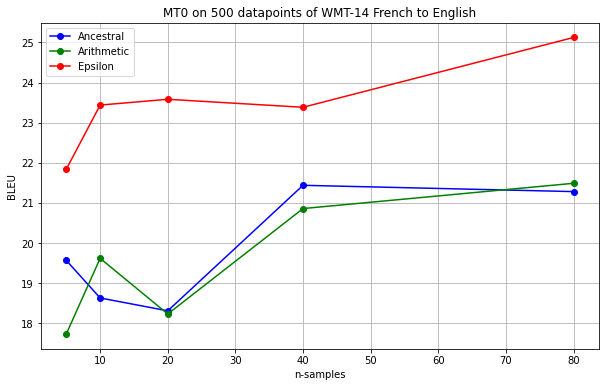

In [30]:
import matplotlib.pyplot as plt

# Data
n_samples = [5, 10, 20, 40, 80]
ancestral = [19.5675, 18.6322, 18.3116, 21.4392, 21.2824]
arithmetic = [17.7349, 19.6191, 18.2331, 20.86, 21.4894]
epsilon = [21.8409, 23.438, 23.5822, 23.3836, 25.1228]

# Plot with increased figure size
plt.figure(figsize=(10, 6))  # Width: 10 inches, Height: 6 inches

# Plot
plt.plot(n_samples, ancestral, marker='o', label='Ancestral', color='blue')
plt.plot(n_samples, arithmetic, marker='o', label='Arithmetic', color='green')
plt.plot(n_samples, epsilon, marker='o', label='Epsilon', color='red')

# Labels and title
plt.xlabel('n-samples')
plt.ylabel('BLEU')
plt.title('MT0 on 500 datapoints of WMT-14 French to English')
plt.legend()

# Show plot
plt.grid(True)
plt.show()


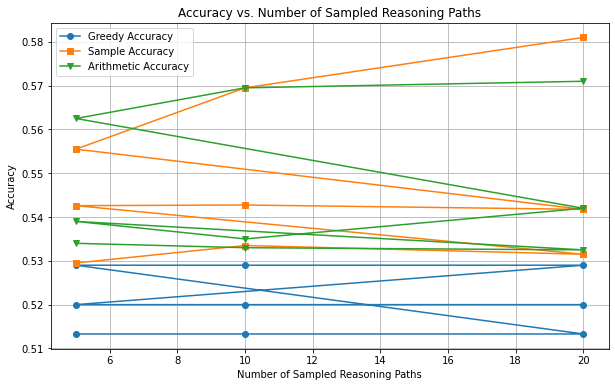

In [31]:
import matplotlib.pyplot as plt

# Data
temperatures = [0.5, 0.5, 0.5, 0.7, 0.7, 0.7, 1.0, 1.0, 1.0]
num_samples = [5, 10, 20, 5, 10, 20, 5, 10, 20]
greedy_accuracy = [0.5133, 0.5133, 0.5133, 0.529, 0.529, 0.529, 0.52, 0.52, 0.52]
sample_accuracy = [0.5295, 0.5335, 0.5315, 0.5426, 0.54275, 0.54175, 0.5555, 0.5695, 0.581]
arithmetic_accuracy = [0.534, 0.533, 0.5325, 0.539, 0.535, 0.542, 0.5625, 0.5695, 0.571]

# Plot
plt.figure(figsize=(10, 6))
plt.plot(num_samples, greedy_accuracy, marker='o', label='Greedy Accuracy')
plt.plot(num_samples, sample_accuracy, marker='s', label='Sample Accuracy')
plt.plot(num_samples, arithmetic_accuracy, marker='v', label='Arithmetic Accuracy')

plt.xlabel('Number of Sampled Reasoning Paths')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. Number of Sampled Reasoning Paths')
plt.legend()
plt.grid(True)
plt.show()